# 05 Model Evaluation

Evaluate and compare models using suitable classification metrics and confusion matrices.

Add the executed analysis, outputs, and findings for this stage below.

TELCO CUSTOMER CHURN CLASSIFICATION
STAGE 5: MODEL EVALUATION

Dataset successfully loaded!
Testing samples: 1409

All trained models loaded successfully!

[1] MODEL PERFORMANCE

Logistic Regression
Accuracy : 0.7999
Precision: 0.6544
Recall   : 0.5214
F1-Score : 0.5804

Decision Tree
Accuracy : 0.7736
Precision: 0.5846
Recall   : 0.5080
F1-Score : 0.5436

Random Forest
Accuracy : 0.7956
Precision: 0.6443
Recall   : 0.5134
F1-Score : 0.5714

[2] MODEL COMPARISON
              Model Accuracy Precision Recall F1-Score
Logistic Regression   0.7999    0.6544 0.5214   0.5804
      Decision Tree   0.7736    0.5846 0.5080   0.5436
      Random Forest   0.7956    0.6443 0.5134   0.5714

[3] MODEL COMPARISON VISUALIZATION


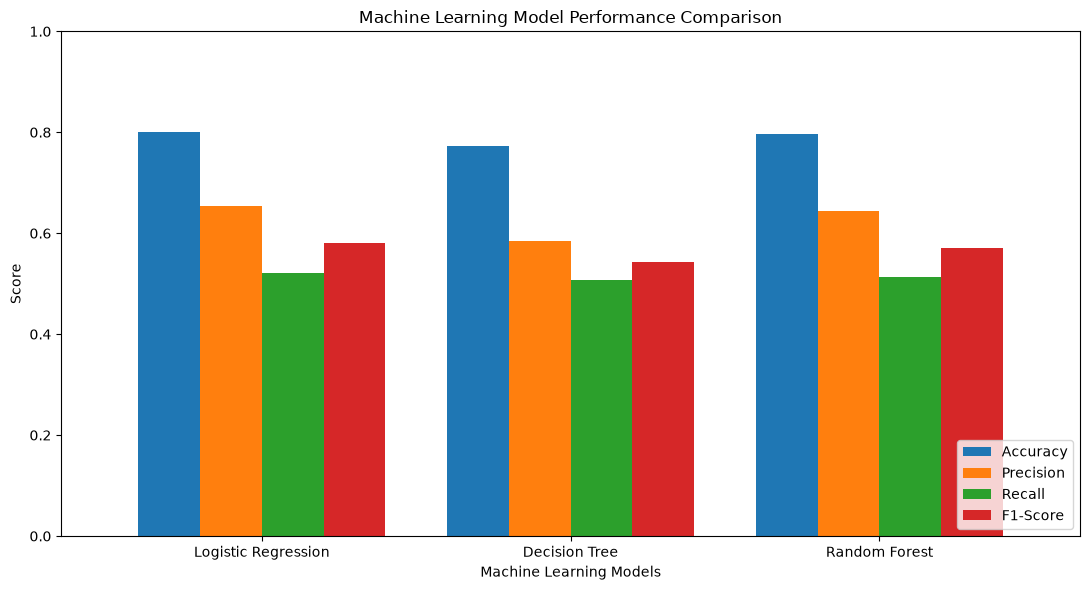


[4] CONFUSION MATRIX


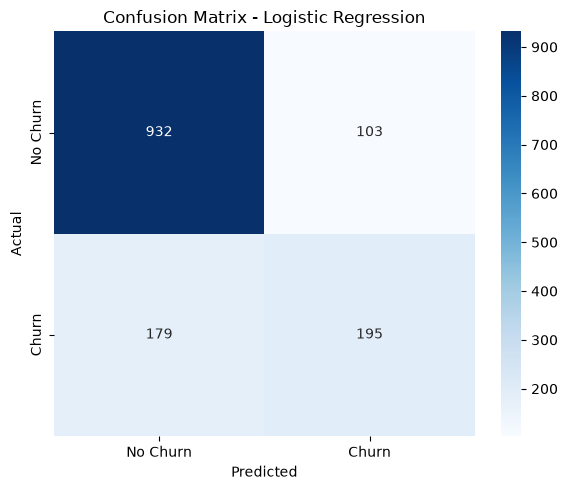

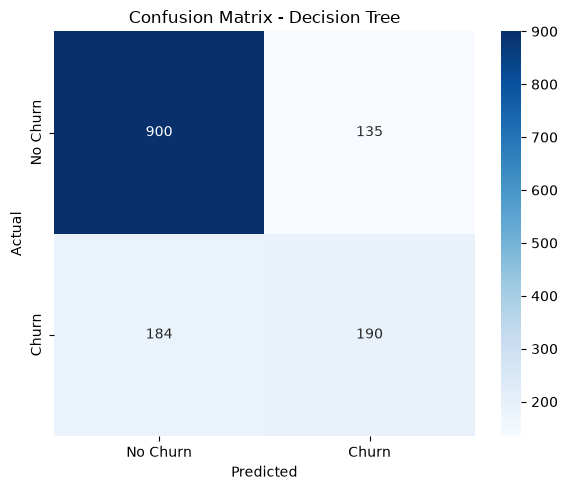

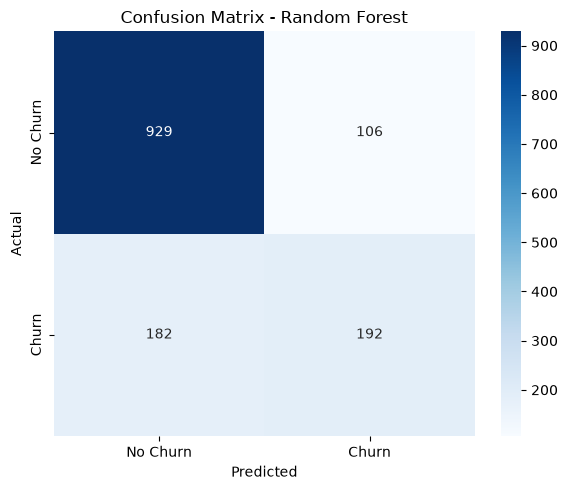


[5] CLASSIFICATION REPORT

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.83      0.87      0.85      1035
       Churn       0.58      0.51      0.54       374

    accuracy                           0.77      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.77      0.77      1409


Random Forest
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.64      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1

In [1]:

# ============================================================
# TELCO CUSTOMER CHURN CLASSIFICATION
# STAGE 5: MODEL EVALUATION
# ============================================================

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("TELCO CUSTOMER CHURN CLASSIFICATION")
print("STAGE 5: MODEL EVALUATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv("../data/cleaned_telco_churn.csv")

print("\nDataset successfully loaded!")

# ------------------------------------------------------------
# 2. PREPARE DATA
# ------------------------------------------------------------

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Testing samples: {len(X_test)}")

# ------------------------------------------------------------
# 3. LOAD TRAINED MODELS
# ------------------------------------------------------------

model_dir = Path("../models")

models = {
    "Logistic Regression": joblib.load(
        model_dir / "logistic_regression.pkl"
    ),

    "Decision Tree": joblib.load(
        model_dir / "decision_tree.pkl"
    ),

    "Random Forest": joblib.load(
        model_dir / "random_forest.pkl"
    )
}

print("\nAll trained models loaded successfully!")

# ------------------------------------------------------------
# 4. MODEL EVALUATION
# ------------------------------------------------------------

print("\n[1] MODEL PERFORMANCE")

results = []
predictions = {}

for model_name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"\n{model_name}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

# ------------------------------------------------------------
# 5. COMPARISON TABLE
# ------------------------------------------------------------

print("\n[2] MODEL COMPARISON")

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1-Score": "{:.4f}".format
        }
    )
)

# ------------------------------------------------------------
# 6. VISUALIZE MODEL COMPARISON
# ------------------------------------------------------------

print("\n[3] MODEL COMPARISON VISUALIZATION")

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

image_dir = Path("../images")
image_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(image_dir / "07_model_comparison.png")
plt.show()

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

print("\n[4] CONFUSION MATRIX")

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        + "_confusion_matrix.png"
    )

    plt.savefig(image_dir / filename)
    plt.show()

# ------------------------------------------------------------
# 8. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n[5] CLASSIFICATION REPORT")

for model_name, y_pred in predictions.items():

    print(f"\n{model_name}")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

# ------------------------------------------------------------
# 9. BEST MODEL BASED ON F1-SCORE
# ------------------------------------------------------------

print("\n[6] BEST MODEL")

best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print(f"Best Model: {best_model['Model']}")
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1-Score: {best_model['F1-Score']:.4f}")

# Simpan hasil evaluasi
results_df.to_csv(
    "../data/model_evaluation_results.csv",
    index=False
)

print("\n" + "=" * 60)
print("STAGE 5 COMPLETED SUCCESSFULLY!")
print("=" * 60)

print("Evaluation results saved successfully!")
